# Reference mapping: Zemke → Tian in the joint scHi-C + DNA methylation space

Project the 22,240 cells of **Zemke et al.** onto the **Tian et al.** atlas
(126,288 cells) **without refitting the model**, using both modalities together.

The atlas is a map that already exists. We are not redrawing it — we are placing
new cells onto it and asking which atlas cells each one landed next to.

---

### Data

This notebook needs a data bundle, downloadable from

> ### https://spinmcia.lji.org/data

Download it, unpack it, and set `DATA_DIR` in the first cell to that folder.
No data is distributed with this notebook.

Everything below is computed from the published files — per-feature statistics,
the projection, the depth vector and the UMAP are all derived here, not supplied.
A first run therefore takes roughly **35–45 minutes**, most of it a single pass
over the Tian Hi-C matrix. Results are cached into `CACHE_DIR` as they are
produced, so any rerun is a couple of minutes.

Expected layout under `DATA_DIR` (14 files):

    Preprocessed_Tian/   Tian_All_Cells_200kb_scHiC_kept_features.npy
                         Tian_All_Cells_dna_methylation_kept_features.npy
                         Tian_All_Cells_metadata.csv
    Preprocessed_Zemke/  Zemke_200kb_scHiC.h5ad
                         Zemke_200kb_scHiC_kept_features.npy
                         Zemke_100kb_methylation.h5ad
                         Zemke_100kb_dna_methylation_kept_features.npy
                         Zemke_metadata.csv
    SpinMCIA_Outputs_Tian_200kb/
                         block_loadings_HiC.csv
                         block_loadings_SecondModality.csv
                         block_scores_HiC.csv
                         block_scores_SecondModality.csv
                         global_scores.csv
                         block_score_weights.csv

---

### Steps

1. Match features between the two datasets
2. Load the atlas's loadings and block weights, and verify the combination rule
3. Reference per-feature statistics
4. Project reference and query through the stored loadings
5. Calibrate our coordinates onto the atlas's real ones
6. Combine the two blocks into consensus scores
7. Transfer labels from the 15 nearest atlas neighbours
8. Control: is placement driven by sequencing depth?
9. UMAP
10. Figures — UMAPs, uncertainty, and the confusion matrix

Zemke's own cell-type labels appear only from step 7 onward, and only to *score*
the result. They never influence where a cell is placed.

In [1]:
# ============================ EDIT THIS ============================
DATA_DIR = "./sample_data/RefMap_Tian_Zemke"   # from https://spinmcia.lji.org/data
# ===================================================================

import os, csv, time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
%matplotlib inline

DATA_DIR = os.path.abspath(os.environ.get("SPINMCIA_DATA", DATA_DIR))
RES = "200kb"
PT = f"{DATA_DIR}/Preprocessed_Tian"
PQ = f"{DATA_DIR}/Preprocessed_Zemke"
SO = f"{DATA_DIR}/SpinMCIA_Outputs_Tian_{RES}"
# The two Tian matrices are 50 GB and 23 GB, so they are NOT part of sample_data.
# Point this at wherever they live; on the cluster that is the release itself.
TIAN_RAW_DIR = os.environ.get("TIAN_RAW_DIR",
    "/home/calimarandi/schic_methods/SpinMCIA_Release/Zenodo/"
    "sc_HiC_DNA_Methylation/Tian/All_Cells/preprocessed_data")

CACHE_DIR = os.path.abspath(os.environ.get("SPINMCIA_CACHE", "./refmap_cache"))
os.makedirs(CACHE_DIR, exist_ok=True)

NPC, K, STEP, NBINS_MET = 30, 15, 2500, 28760

def load_matrix(base, ncol=NPC):
    # read a SpinMCIA output as .npy if present, else the original .csv
    if os.path.isfile(base + ".npy"):
        return np.load(base + ".npy").astype(float)[:, :ncol]
    with open(base + ".csv") as f:
        f.readline()
        return np.array([l.rstrip("\r\n").split(",")[:ncol] for l in f], float)

def have(base):
    return os.path.isfile(base + ".npy") or os.path.isfile(base + ".csv")

H5_T_HIC = f"{TIAN_RAW_DIR}/{RES}/Tian_All_Cells_{RES}_scHiC.h5ad"
H5_T_MET = f"{TIAN_RAW_DIR}/Tian_All_Cells_dna_methylation.h5ad"
H5_Q_HIC = f"{PQ}/Zemke_{RES}_scHiC.h5ad"
H5_Q_MET = f"{PQ}/Zemke_100kb_methylation.h5ad"

REQUIRED = [
    f"{PT}/Tian_All_Cells_{RES}_scHiC_kept_features.npy",
    f"{PT}/Tian_All_Cells_dna_methylation_kept_features.npy",
    f"{PT}/Tian_All_Cells_metadata.csv",
    H5_Q_HIC, f"{PQ}/Zemke_{RES}_scHiC_kept_features.npy",
    H5_Q_MET, f"{PQ}/Zemke_100kb_dna_methylation_kept_features.npy",
    f"{PQ}/Zemke_metadata.csv",
    f"{SO}/block_score_weights.csv",
]
REQUIRED += [b + ".csv" for b in (f"{SO}/block_loadings_HiC",
                                  f"{SO}/block_loadings_SecondModality",
                                  f"{SO}/block_scores_HiC",
                                  f"{SO}/block_scores_SecondModality",
                                  f"{SO}/global_scores") if not have(b)]

missing = [p for p in REQUIRED if not os.path.isfile(p)]
if missing:
    raise FileNotFoundError(
        "Missing input files:\n  " +
        "\n  ".join(os.path.relpath(p, DATA_DIR) for p in missing) +
        f"\n\nDATA_DIR is currently:\n  {DATA_DIR}\n"
        "Download the data from https://spinmcia.lji.org/data and point DATA_DIR at it.")

import h5py
HAVE_TIAN_RAW = os.path.isfile(H5_T_HIC) and os.path.isfile(H5_T_MET)
HAVE_STATS    = os.path.isfile(f"{CACHE_DIR}/ref_stats.npz")

print(f"DATA_DIR     : {DATA_DIR}")
print(f"TIAN_RAW_DIR : {TIAN_RAW_DIR}")
print(f"CACHE_DIR    : {CACHE_DIR}   (written here, never an input)")
print(f"\n14 sample_data files present")
print(f"Tian raw matrices (50G + 23G): {'found' if HAVE_TIAN_RAW else 'NOT FOUND'}")
if not HAVE_TIAN_RAW and not HAVE_STATS:
    for _ln in [
        "",
        "  Steps 3 and 4 need the two Tian matrices:",
        "      Tian_All_Cells_200kb_scHiC.h5ad       (50 GB)",
        "      Tian_All_Cells_dna_methylation.h5ad   (23 GB)",
        "  They are part of the SpinMCIA release and are too large to ship as",
        "  sample data. Download them from https://spinmcia.lji.org/data and set",
        "  TIAN_RAW_DIR above to the folder holding them.",
    ]:
        print(_ln)

DATA_DIR     : /home/calimarandi/schic_methods/SpinMCIA_Release/SpinMCIA_GitHub/tutorials/sample_data/RefMap_Tian_Zemke
TIAN_RAW_DIR : /home/calimarandi/schic_methods/SpinMCIA_Release/Zenodo/sc_HiC_DNA_Methylation/Tian/All_Cells/preprocessed_data
CACHE_DIR    : /home/calimarandi/schic_methods/SpinMCIA_Release/SpinMCIA_GitHub/tutorials/refmap_cache   (written here, never an input)

14 sample_data files present
Tian raw matrices (50G + 23G): found


## 1. Match features

Both datasets are binned on hg38, so bin-pair *i* in Tian is the same genomic
pair as bin-pair *i* in Zemke. Matching is an intersection of the two
kept-feature lists — no liftOver anywhere.

In [2]:
kf  = np.load(f"{PT}/Tian_All_Cells_{RES}_scHiC_kept_features.npy")
qkf = np.load(f"{PQ}/Zemke_{RES}_scHiC_kept_features.npy")
sh_hic = np.intersect1d(kf, qkf)
ko = np.argsort(kf);  rc_hic = ko[np.searchsorted(kf[ko],  sh_hic)]
qo = np.argsort(qkf); qc_hic = qo[np.searchsorted(qkf[qo], sh_hic)]
assert np.array_equal(kf[rc_hic], sh_hic) and np.array_equal(qkf[qc_hic], sh_hic)

mr = np.load(f"{PT}/Tian_All_Cells_dna_methylation_kept_features.npy")
mq = np.zeros(NBINS_MET, bool)
mq[np.load(f"{PQ}/Zemke_100kb_dna_methylation_kept_features.npy")] = True
shm = mr & mq
cr, cq = np.cumsum(mr) - 1, np.cumsum(mq) - 1
rc_met, qc_met = cr[shm], cq[shm]

print(f"Hi-C         Tian {kf.size:>7,}  Zemke {qkf.size:>7,}  shared {sh_hic.size:>7,} "
      f"({100*sh_hic.size/kf.size:.2f}% of Tian)")
print(f"methylation  Tian {int(mr.sum()):>7,}  Zemke {int(mq.sum()):>7,}  "
      f"shared {int(shm.sum()):>7,} ({100*shm.sum()/mr.sum():.2f}% of Tian)")

Hi-C         Tian  82,712  Zemke 114,669  shared  82,646 (99.92% of Tian)
methylation  Tian  23,872  Zemke  26,096  shared  23,844 (99.88% of Tian)


## 2. The atlas's loadings and block weights

The loadings are the directions that define the map. The block weights say how
the two modalities combine into a consensus score:

$$\text{global}_j = w^{\text{HiC}}_j \, t^{\text{HiC}}_j + w^{\text{meth}}_j \, t^{\text{meth}}_j,
\qquad (w^{\text{HiC}}_j)^2 + (w^{\text{meth}}_j)^2 = 1$$

We don't assume that rule — we check it against the atlas's own stored scores.

In [3]:
wmap = {r[0]: np.array(r[1:], float)
        for r in list(csv.reader(open(f"{SO}/block_score_weights.csv")))[1:]}
hk = [k for k in wmap if "hic" in k.lower()][0]
mk = [k for k in wmap if k != hk][0]
w_hic, w_met = wmap[hk][:NPC], wmap[mk][:NPC]

Sh = load_matrix(f"{SO}/block_scores_HiC")
Sm = load_matrix(f"{SO}/block_scores_SecondModality")
Sg = load_matrix(f"{SO}/global_scores")

print(f"w_hic  {np.round(w_hic[:6], 4)}")
print(f"w_meth {np.round(w_met[:6], 4)}")
print(f"max |norm - 1| over {NPC} components: {np.abs(np.hypot(w_hic, w_met) - 1).max():.2e}")
print(f"\natlas scores {Sg.shape}")
print(f"max |global - (w_hic*hic + w_meth*meth)| = "
      f"{np.abs(Sg - (Sh*w_hic + Sm*w_met)).max():.2e}   <- the rule, confirmed")

w_hic  [0.4485 0.3423 0.3813 0.3918 0.4588 0.4872]
w_meth [0.8938 0.9396 0.9244 0.92   0.8885 0.8733]
max |norm - 1| over 30 components: 2.22e-16

atlas scores (126288, 30)
max |global - (w_hic*hic + w_meth*meth)| = 1.11e-16   <- the rule, confirmed


## 3. Reference per-feature statistics

A loading only means something applied to data prepared the way the atlas
prepared it. Methylation is mean-centred; Hi-C is closest to a z-score, though
not exactly — step 5 absorbs the remainder.

Computed here with one pass over each Tian matrix. The Hi-C pass reads 4.4
billion nonzeros, so it takes ~12 minutes the first time; it is cached after.

Per-feature sums are accumulated straight off the sparse values with
`np.bincount` — the matrix is never densified.

In [4]:
stat_cache = f"{CACHE_DIR}/ref_stats.npz"
if not os.path.isfile(stat_cache) and not HAVE_TIAN_RAW:
    raise FileNotFoundError(
        "This step reads the two Tian matrices. Set TIAN_RAW_DIR in the first "
        "cell to the folder containing Tian_All_Cells_200kb_scHiC.h5ad and "
        "Tian_All_Cells_dna_methylation.h5ad (from https://spinmcia.lji.org/data).")
if os.path.isfile(stat_cache):
    z = np.load(stat_cache)
    mu_hic_all, sd_hic_all, mu_met_all, rowsums = (
        z["mu_hic"], z["sd_hic"], z["mu_met"], z["rowsums"])
    print("loaded cached reference statistics")
else:
    t0 = time.time()
    with h5py.File(H5_T_HIC, "r") as h:
        ptr = h["X/indptr"][:]
        NREF_ = ptr.size - 1
        P = tuple(h["X"].attrs["shape"])[1]
        s1 = np.zeros(P); s2 = np.zeros(P); rowsums = np.zeros(NREF_)
        for a0 in range(0, NREF_, 3000):
            b = min(a0 + 3000, NREF_)
            s, e = int(ptr[a0]), int(ptr[b])
            dat = np.asarray(h["X/data"][s:e], float)
            idx = np.asarray(h["X/indices"][s:e])
            rid = np.repeat(np.arange(b - a0), np.diff(ptr[a0:b+1]).astype(np.int64))
            rowsums[a0:b] = np.bincount(rid, weights=dat, minlength=b - a0)
            s1 += np.bincount(idx, weights=dat, minlength=P)
            s2 += np.bincount(idx, weights=dat*dat, minlength=P)
            if (a0 // 3000) % 10 == 0:
                print(f"  Hi-C   {a0:>7,}/{NREF_:,}   {time.time()-t0:5.0f}s")
    mu_hic_all = s1 / NREF_
    sd_hic_all = np.sqrt(np.maximum(s2/NREF_ - mu_hic_all**2, 0))
    sd_hic_all[sd_hic_all < 1e-12] = 1.0

    with h5py.File(H5_T_MET, "r") as h:
        X = h["X"]; N, PM = X.shape
        s1 = np.zeros(PM)
        for a0 in range(0, N, 4000):
            s1 += np.asarray(X[a0:min(a0+4000, N), :], float).sum(0)
    mu_met_all = s1 / N
    np.savez(stat_cache, mu_hic=mu_hic_all, sd_hic=sd_hic_all,
             mu_met=mu_met_all, rowsums=rowsums)
    print(f"  computed in {time.time()-t0:.0f}s, cached")

mu_h, sd_h = mu_hic_all[rc_hic], sd_hic_all[rc_hic]
mu_m = mu_met_all[rc_met]

Lh = load_matrix(f"{SO}/block_loadings_HiC")[rc_hic, :]
Lm = load_matrix(f"{SO}/block_loadings_SecondModality")[rc_met, :]
print(f"\nloadings on shared features: Hi-C {Lh.shape}, methylation {Lm.shape}")
print(f"Tian per-cell contacts: median {np.median(rowsums):,.0f}")

loaded cached reference statistics



loadings on shared features: Hi-C (82646, 30), methylation (23844, 30)
Tian per-cell contacts: median 81,942


## 4. Project

Multiply the prepared data by the loadings, reading the matrices in chunks —
a dense Tian Hi-C matrix would be 84 GB. ~15 minutes the first time, cached after.

In [5]:
proj_cache = f"{CACHE_DIR}/projected_scores.npz"
if not os.path.isfile(proj_cache) and not HAVE_TIAN_RAW:
    raise FileNotFoundError("This step also needs the Tian matrices -- see TIAN_RAW_DIR above.")
if os.path.isfile(proj_cache):
    z = np.load(proj_cache)
    Rh_ours, Rm_ours, Qh_ours, Qm_ours = z["Rh"], z["Rm"], z["Qh"], z["Qm"]
    print("loaded cached projection")
else:
    def project(path, ncell, cols, how):
        S = np.zeros((ncell, NPC))
        with h5py.File(path, "r") as h:
            X = h["X"]; dense = isinstance(X, h5py.Dataset)
            if not dense:
                ptr = h["X/indptr"][:]; W = tuple(X.attrs["shape"])[1]
                take = np.full(W, -1, np.int64); take[cols] = np.arange(cols.size)
            for a0 in range(0, ncell, STEP):
                b = min(a0 + STEP, ncell)
                if dense:
                    Xd = np.asarray(X[a0:b, :][:, cols], float)
                else:
                    s, e = int(ptr[a0]), int(ptr[b])
                    dat = np.asarray(h["X/data"][s:e], float)
                    idx = np.asarray(h["X/indices"][s:e])
                    rid = np.repeat(np.arange(b-a0), np.diff(ptr[a0:b+1]).astype(np.int64))
                    keep = take[idx] >= 0
                    Xd = np.zeros((b - a0, cols.size))
                    Xd[rid[keep], take[idx[keep]]] = dat[keep]
                S[a0:b] = (((Xd - mu_h)/sd_h) @ Lh) if how == "hic" else ((Xd - mu_m) @ Lm)
                del Xd
        return S

    NREF = Sg.shape[0]
    with h5py.File(H5_Q_HIC, "r") as h:
        NQ = h["X/indptr"].shape[0] - 1
    t0 = time.time()
    Rh_ours = project(H5_T_HIC, NREF, rc_hic, "hic"); print(f"  ref Hi-C   {time.time()-t0:5.0f}s")
    Rm_ours = project(H5_T_MET, NREF, rc_met, "met"); print(f"  ref meth   {time.time()-t0:5.0f}s")
    Qh_ours = project(H5_Q_HIC, NQ,   qc_hic, "hic"); print(f"  query Hi-C {time.time()-t0:5.0f}s")
    Qm_ours = project(H5_Q_MET, NQ,   qc_met, "met"); print(f"  query meth {time.time()-t0:5.0f}s")
    np.savez(proj_cache, Rh=Rh_ours, Rm=Rm_ours, Qh=Qh_ours, Qm=Qm_ours)

NREF, NQ = Rh_ours.shape[0], Qh_ours.shape[0]
print(f"reference {NREF:,} cells, query {NQ:,} cells")

loaded cached projection
reference 126,288 cells, query 22,240 cells


## 5. Calibrate onto the atlas's real coordinates

Our Hi-C preparation reproduces the atlas's stored scores at r ≈ 0.999, not
exactly. Rather than guess the remaining difference, we fit a linear map from
*our* reference coordinates onto the *stored* ones, and send the query through
the same map.

Fitted on half the atlas, scored on the half it never saw — so the R² below is
an honest out-of-sample number, not a fit statistic.

In [6]:
rng  = np.random.default_rng(0)
perm = rng.permutation(NREF)
fit, hold = perm[:NREF//2], perm[NREF//2:]

def calibrate(ours, stored, name):
    A = np.column_stack([ours, np.ones(len(ours))])
    M, *_ = np.linalg.lstsq(A[fit], stored[fit], rcond=None)
    pred = A @ M
    r2 = np.array([1 - ((stored[hold,j]-pred[hold,j])**2).sum() /
                       ((stored[hold,j]-stored[hold,j].mean())**2).sum()
                   for j in range(NPC)])
    print(f"{name}: held-out R2   min {r2.min():.4f}   median {np.median(r2):.4f}")
    return M, r2

Mh, r2h = calibrate(Rh_ours, Sh, "Hi-C block  ")
Mm, r2m = calibrate(Rm_ours, Sm, "meth block  ")

Qh = np.column_stack([Qh_ours, np.ones(NQ)]) @ Mh
Qm = np.column_stack([Qm_ours, np.ones(NQ)]) @ Mm
print("\nquery carried into the atlas's coordinate system")

Hi-C block  : held-out R2   min 0.9795   median 0.9982


meth block  : held-out R2   min 0.9948   median 0.9986

query carried into the atlas's coordinate system


## 6. Combine the blocks

The reference keeps its **stored** coordinates — we never substitute our own.
Only the query is computed.

In [7]:
Rg = Sg                       # reference: the atlas's real consensus scores
Qg = Qh * w_hic + Qm * w_met  # query: combined with the atlas's own weights
print(f"reference {Rg.shape}, query {Qg.shape}")

reference (126288, 30), query (22240, 30)


## 7. Transfer labels

For each Zemke cell, its 15 nearest atlas neighbours vote. Uncertainty is
1 − (winning label's share): all 15 agreeing gives 0, a cell torn between types
gives a high value.

This is the first point where Zemke's own labels appear, and they are used only
to score the result.

In [8]:
yr = np.array([r["cell_type"] for r in csv.DictReader(open(f"{PT}/Tian_All_Cells_metadata.csv"))])
yq = np.array([r["cluster"]   for r in csv.DictReader(open(f"{PQ}/Zemke_metadata.csv"))])
assert len(yr) == NREF and len(yq) == NQ
print(f"atlas: {len(set(yr))} cell types   query: {len(set(yq))} subclusters\n")

def transfer(Sr, Sq):
    rn = (Sr**2).sum(1)
    pred = np.empty(len(Sq), object); unc = np.zeros(len(Sq)); dk = np.zeros(len(Sq))
    for a0 in range(0, len(Sq), 500):
        q = Sq[a0:a0+500]
        d = rn[None,:] - 2*q@Sr.T + (q**2).sum(1)[:,None]
        ix = np.argpartition(d, K, axis=1)[:, :K]
        for i in range(len(q)):
            u, c = np.unique(yr[ix[i]], return_counts=True)
            pred[a0+i] = u[c.argmax()]; unc[a0+i] = 1 - c.max()/K
            dk[a0+i] = np.sqrt(max(np.sort(d[i, ix[i]])[-1], 0))
    return pred, unc, dk

pred, unc, dist = transfer(Rg, Qg)
print(f"mean uncertainty {unc.mean():.4f}\n")
for t in sorted(set(yq)):
    m = yq == t
    u, c = np.unique(pred[m], return_counts=True)
    o = np.argsort(-c)[:2]
    print(f"  {t:14s} n={m.sum():6d}  unc={unc[m].mean():.3f}   " +
          ", ".join(f"{u[j]} {100*c[j]/m.sum():.0f}%" for j in o))

atlas: 29 cell types   query: 15 subclusters



mean uncertainty 0.0689

  Astro1         n=  1338  unc=0.031   ASC 98%, ODC 1%
  Astro2         n=  1159  unc=0.084   ASC 93%, ODC 6%
  CA             n=   131  unc=0.592   L2/3-IT 60%, Amy-Exc 16%
  DG             n=   310  unc=0.358   Amy-Exc 52%, L2/3-IT 41%
  Endo           n=    73  unc=0.111   EC 85%, MGC 12%
  Micro1         n=  1329  unc=0.013   MGC 99%, ODC 0%
  Micro2         n=  1275  unc=0.028   MGC 99%, ODC 1%
  NR2F2-LAMP5    n=   173  unc=0.464   Lamp5 62%, Vip 19%
  OPC            n=  1118  unc=0.190   OPC 54%, ODC 45%
  Oligo          n= 13188  unc=0.011   ODC 99%, MGC 0%
  PVALB          n=   180  unc=0.234   Pvalb 95%, Sst 3%
  SST            n=   195  unc=0.211   Sst 94%, Pvalb 4%
  SUB            n=  1298  unc=0.348   L2/3-IT 52%, L5-IT 13%
  VIP            n=   306  unc=0.394   Vip 86%, Sncg 13%
  VLMC           n=   167  unc=0.328   VLMC 81%, PC 7%


## 8. Control: is this just sequencing depth?

Zemke has ~3.7× fewer Hi-C contacts per cell than Tian. If shallowness were
pushing cells around, position would track depth. We want |r| well under 0.2.

In [9]:
dpath = f"{CACHE_DIR}/zemke_depth.npy"
if os.path.isfile(dpath):
    qdep = np.load(dpath)
else:
    with h5py.File(H5_Q_HIC, "r") as h:
        ptr = h["X/indptr"][:]; qdep = np.zeros(NQ)
        for a0 in range(0, NQ, 4000):
            b = min(a0+4000, NQ); s, e = int(ptr[a0]), int(ptr[b])
            dat = np.asarray(h["X/data"][s:e], float)
            rid = np.repeat(np.arange(b-a0), np.diff(ptr[a0:b+1]).astype(np.int64))
            qdep[a0:b] = np.bincount(rid, weights=dat, minlength=b-a0)
    np.save(dpath, qdep)

ld = np.log10(np.maximum(qdep, 1))
print(f"Zemke median {np.median(qdep):,.0f} contacts/cell")
print(f"Tian  median {np.median(rowsums):,.0f} contacts/cell")
print(f"ratio {np.median(qdep)/np.median(rowsums):.3f}")
print(f"\nr(log10 depth, uncertainty) = {np.corrcoef(ld, unc)[0,1]:+.3f}")

Zemke median 21,871 contacts/cell
Tian  median 81,942 contacts/cell
ratio 0.267

r(log10 depth, uncertainty) = -0.054


## 9. UMAP

For display only — every number above lives in the 30-dimensional space.
Cached, because fitting on 126,288 cells is the slow part.

In [10]:
ef, eqf = f"{CACHE_DIR}/umap_ref.npy", f"{CACHE_DIR}/umap_query.npy"
if os.path.isfile(ef) and os.path.isfile(eqf):
    Er, Eq = np.load(ef), np.load(eqf)
    print("loaded cached embedding")
else:
    import umap
    red = umap.UMAP(n_neighbors=30, min_dist=0.3, n_jobs=-1, verbose=True)
    Er = red.fit_transform(Rg); Eq = red.transform(Qg)
    np.save(ef, Er); np.save(eqf, Eq)

print(f"r(log10 depth, UMAP-1) = {np.corrcoef(ld, Eq[:,0])[0,1]:+.3f}")
print(f"r(log10 depth, UMAP-2) = {np.corrcoef(ld, Eq[:,1])[0,1]:+.3f}")
print("   |r| under ~0.2 means coverage is not driving where cells land")

loaded cached embedding
r(log10 depth, UMAP-1) = -0.123
r(log10 depth, UMAP-2) = +0.013
   |r| under ~0.2 means coverage is not driving where cells land


## 10a. UMAPs

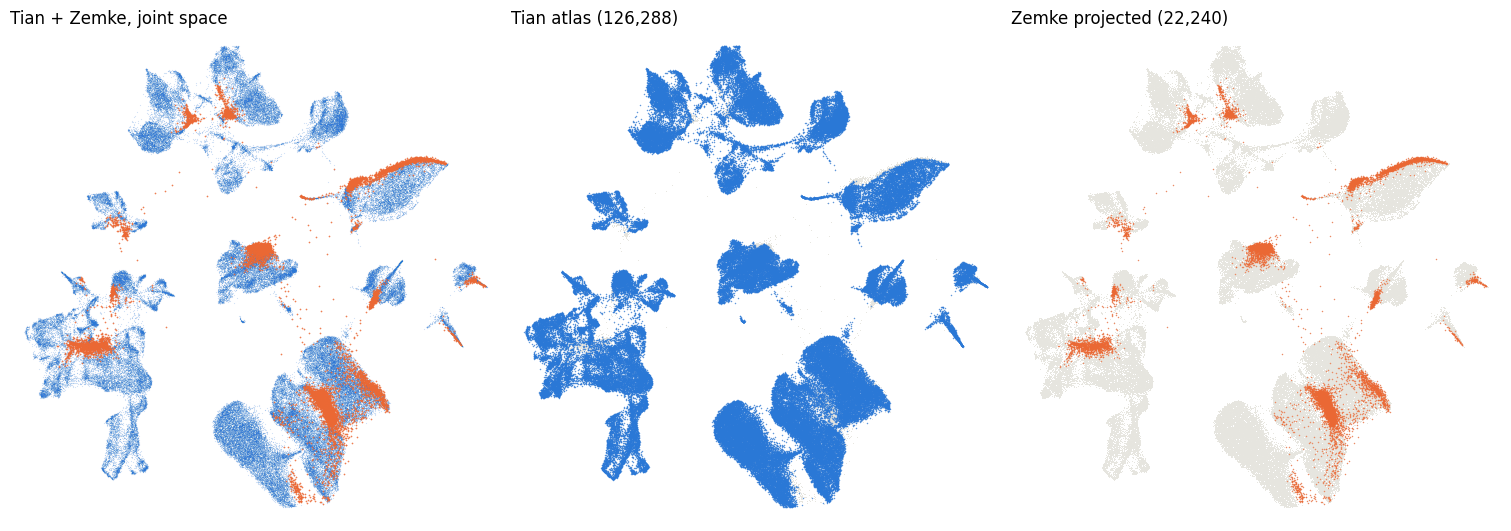

In [11]:
BLUE, ORANGE, GHOST = "#2a78d6", "#eb6834", "#e6e5df"
ALL = np.vstack([Er, Eq]); pad = 0.03
XL = (ALL[:,0].min()-pad*np.ptp(ALL[:,0]), ALL[:,0].max()+pad*np.ptp(ALL[:,0]))
YL = (ALL[:,1].min()-pad*np.ptp(ALL[:,1]), ALL[:,1].max()+pad*np.ptp(ALL[:,1]))

fig, axes = plt.subplots(1, 3, figsize=(15, 5.2), constrained_layout=True)
for ax, title in zip(axes, ["Tian + Zemke, joint space",
                            f"Tian atlas ({len(Er):,})",
                            f"Zemke projected ({len(Eq):,})"]):
    ax.set_xlim(*XL); ax.set_ylim(*YL); ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values(): s.set_visible(False)
    ax.set_title(title, loc="left")
axes[0].scatter(Er[:,0], Er[:,1], s=0.7, c=BLUE,   lw=0, alpha=0.22, rasterized=True)
axes[0].scatter(Eq[:,0], Eq[:,1], s=1.5, c=ORANGE, lw=0, alpha=0.85, rasterized=True)
for ax, pts, col in ((axes[1], Er, BLUE), (axes[2], Eq, ORANGE)):
    ax.scatter(ALL[:,0], ALL[:,1], s=0.5, c=GHOST, lw=0, rasterized=True)
    ax.scatter(pts[:,0], pts[:,1], s=1.2, c=col, lw=0, alpha=0.7, rasterized=True)
plt.show()

## 10b. Uncertainty, and the depth control

Left: where the atlas is confident. Right: the same cells coloured by how much
Hi-C data each one has. If the right panel showed a gradient matching the left,
the result would be an artifact of coverage.

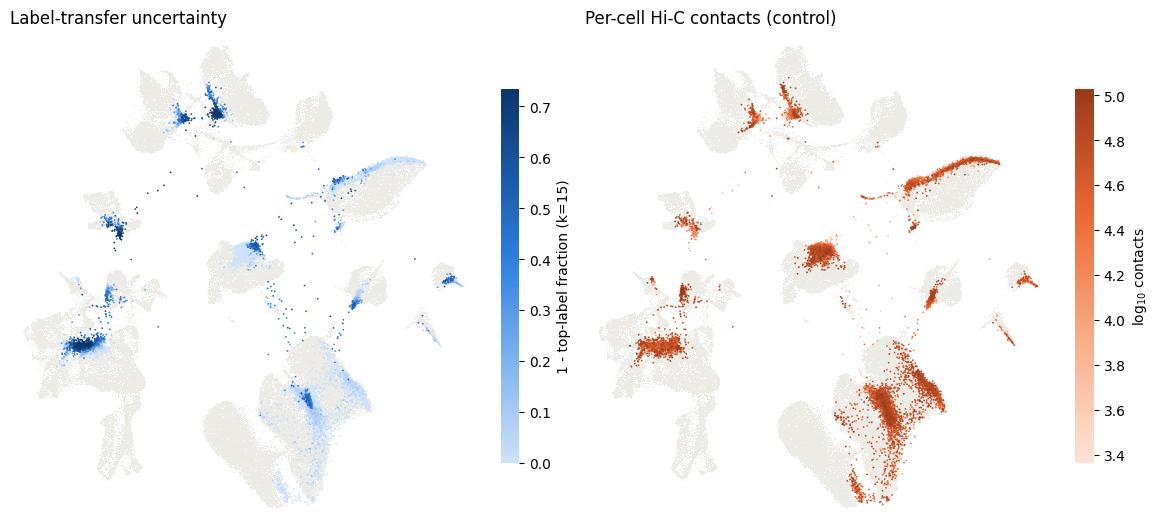

In [12]:
RAMP = ["#cde2fb","#b7d3f6","#9ec5f4","#86b6ef","#6da7ec","#5598e7","#3987e5",
        "#2a78d6","#256abf","#1c5cab","#184f95","#104281","#0d366b"]
CM_B = LinearSegmentedColormap.from_list("b", RAMP)
CM_O = LinearSegmentedColormap.from_list("o", ["#fde3d6","#f8ad87","#eb6834","#993a1a"])

fig, axes = plt.subplots(1, 2, figsize=(11.5, 5.2), constrained_layout=True)
for ax, vals, cm, lab, title in (
        (axes[0], unc, CM_B, "1 - top-label fraction (k=15)", "Label-transfer uncertainty"),
        (axes[1], ld,  CM_O, "log$_{10}$ contacts", "Per-cell Hi-C contacts (control)")):
    ax.set_xlim(*XL); ax.set_ylim(*YL); ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values(): s.set_visible(False)
    ax.scatter(Er[:,0], Er[:,1], s=0.5, c="#ecebe5", lw=0, rasterized=True)
    o = np.argsort(vals)
    sc = ax.scatter(Eq[o,0], Eq[o,1], s=1.6, c=vals[o], cmap=cm, lw=0,
                    norm=Normalize(*np.percentile(vals, [1, 99])), rasterized=True)
    cb = fig.colorbar(sc, ax=ax, fraction=0.04); cb.set_label(lab)
    cb.outline.set_visible(False)
    ax.set_title(title, loc="left")
plt.show()

## 10c. Confusion matrix

Rows grouped biologically with the three novel subclusters last; columns ordered
so each row's dominant assignment falls near the diagonal.

CA, DG and SUB are hippocampal excitatory types with **no counterpart in the
Tian atlas**. They should, correctly, fail to land anywhere — and they scatter
across unrelated excitatory labels instead of being confidently mislabelled.

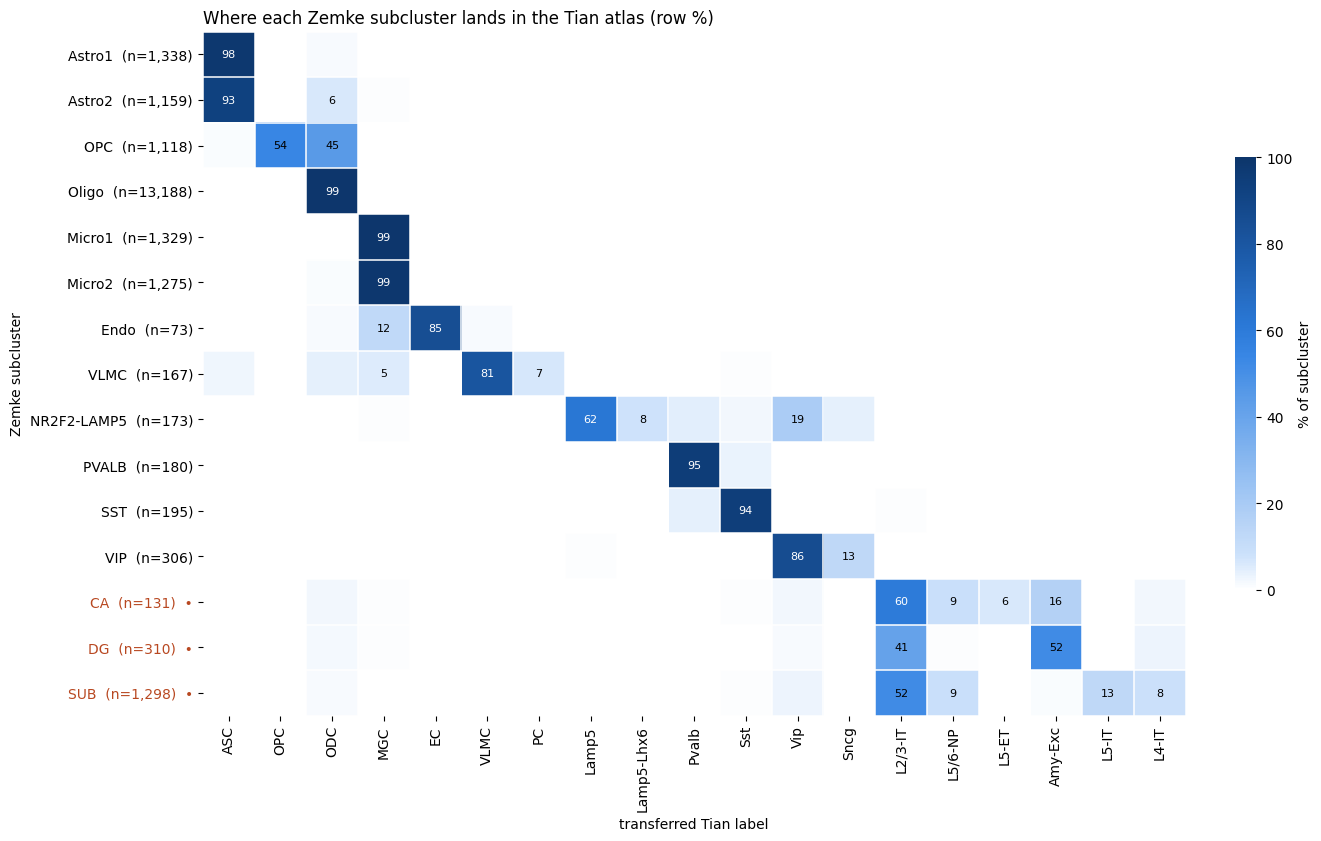

In [13]:
NOVEL = {"CA","DG","SUB"}
ROW_GROUPS = ["Astro1","Astro2","OPC","Oligo","Micro1","Micro2","Endo","VLMC",
              "NR2F2-LAMP5","PVALB","SST","VIP","CA","DG","SUB"]
present = set(yq)
qt = [t for t in ROW_GROUPS if t in present] + [t for t in sorted(present) if t not in ROW_GROUPS]

cand = sorted(set(pred))
share = np.zeros((len(qt), len(cand)))
for i, a in enumerate(qt):
    m = yq == a
    for j, b in enumerate(cand):
        share[i, j] = (pred[m] == b).sum() / max(m.sum(), 1)

kj = [j for j in range(len(cand)) if share[:, j].max() >= 0.05]
kj.sort(key=lambda j: (int(np.argmax(share[:, j])), -float(share[:, j].max())))
keep = [cand[j] for j in kj]; M = share[:, kj]

CM_Z = LinearSegmentedColormap.from_list("bz", ["#ffffff"] + RAMP)
fig, ax = plt.subplots(figsize=(0.46*len(keep)+4.4, 0.40*len(qt)+2.3),
                       constrained_layout=True)
im = ax.imshow(M*100, cmap=CM_Z, aspect="auto", vmin=0, vmax=100)
ax.set_xticks(range(len(keep))); ax.set_xticklabels(keep, rotation=90)
ax.set_yticks(range(len(qt)))
ax.set_yticklabels([f"{t}  (n={int((yq==t).sum()):,})" + ("  •" if t in NOVEL else "")
                    for t in qt])
for i, t in enumerate(qt):
    if t in NOVEL: ax.get_yticklabels()[i].set_color("#b84821")
ax.set_xlabel("transferred Tian label"); ax.set_ylabel("Zemke subcluster")
for s in ax.spines.values(): s.set_visible(False)
ax.set_xticks(np.arange(-.5, len(keep), 1), minor=True)
ax.set_yticks(np.arange(-.5, len(qt), 1), minor=True)
ax.grid(which="minor", color="white", lw=1.1); ax.tick_params(which="minor", length=0)
for i in range(len(qt)):
    for j in range(len(keep)):
        if M[i, j] >= 0.05:
            ax.text(j, i, f"{M[i,j]*100:.0f}", ha="center", va="center",
                    fontsize=8, color="white" if M[i,j] > 0.55 else "black")
cb = fig.colorbar(im, ax=ax, fraction=0.022); cb.set_label("% of subcluster")
cb.outline.set_visible(False)
ax.set_title("Where each Zemke subcluster lands in the Tian atlas (row %)", loc="left")
plt.show()

## 11. Supplementary Figure 41 — where each subcluster went, and how confident

Section 7 gave each cell a label by majority vote among its 15 nearest atlas
neighbours. That says *where* cells went, not whether the vote was convincing.

Here each neighbour is weighted by a Gaussian on its distance — bandwidth set
per cell from the median of its own neighbour distances — so confidence becomes
continuous and rewards a cell sitting deep inside a cluster over one clinging to
its edge. The **margin** (winner minus runner-up) is computed too: it separates
"torn between two types" from "one winner, diffuse rest".

The figure then shows both facts at once:

* dot **area** — share of that subcluster's cells assigned to that label
* dot **colour** — mean confidence of *those particular* cells

Note that colour is conditioned on the assignment, so within each row the
dominant column over-represents cells whose vote had a clear winner.


In [14]:
# distance-weighted confidence and margin, from the consensus scores above
classes = np.unique(yr)
cls_ix = {c: i for i, c in enumerate(classes)}
yr_i = np.array([cls_ix[c] for c in yr])
rn = (Rg ** 2).sum(1)

conf_w = np.zeros(len(Qg))
margin_w = np.zeros(len(Qg))
pred_w = np.empty(len(Qg), dtype=object)

t0 = time.time()
for a in range(0, len(Qg), 500):
    q = Qg[a:a + 500]
    d2 = rn[None, :] - 2 * q @ Rg.T + (q ** 2).sum(1)[:, None]
    np.maximum(d2, 0, out=d2)
    ix = np.argpartition(d2, K, axis=1)[:, :K]
    for i in range(len(q)):
        nb = ix[i]
        d = np.sqrt(d2[i, nb])
        h = np.median(d)
        if h <= 0:
            h = d.max() if d.max() > 0 else 1.0
        w = np.exp(-0.5 * (d / h) ** 2)          # Gaussian, per-cell bandwidth
        agg = np.bincount(yr_i[nb], weights=w, minlength=len(classes))
        o = np.argsort(-agg)
        conf_w[a + i] = agg[o[0]] / w.sum()
        margin_w[a + i] = (agg[o[0]] - (agg[o[1]] if len(o) > 1 else 0.0)) / w.sum()
        pred_w[a + i] = classes[o[0]]
    if (a // 500) % 20 == 0:
        print(f"  {a}/{len(Qg)}   {time.time()-t0:5.0f}s", flush=True)

novel_mask = np.array([t in {"CA", "DG", "SUB"} for t in yq])
print(f"\ndone in {time.time()-t0:.0f}s")
print(f"median confidence, subclusters the atlas contains : {np.median(conf_w[~novel_mask]):.3f}")
print(f"median confidence, subclusters it does not        : {np.median(conf_w[novel_mask]):.3f}")


  0/22240       1s


  10000/22240      18s


  20000/22240      36s



done in 39s
median confidence, subclusters the atlas contains : 1.000
median confidence, subclusters it does not        : 0.608


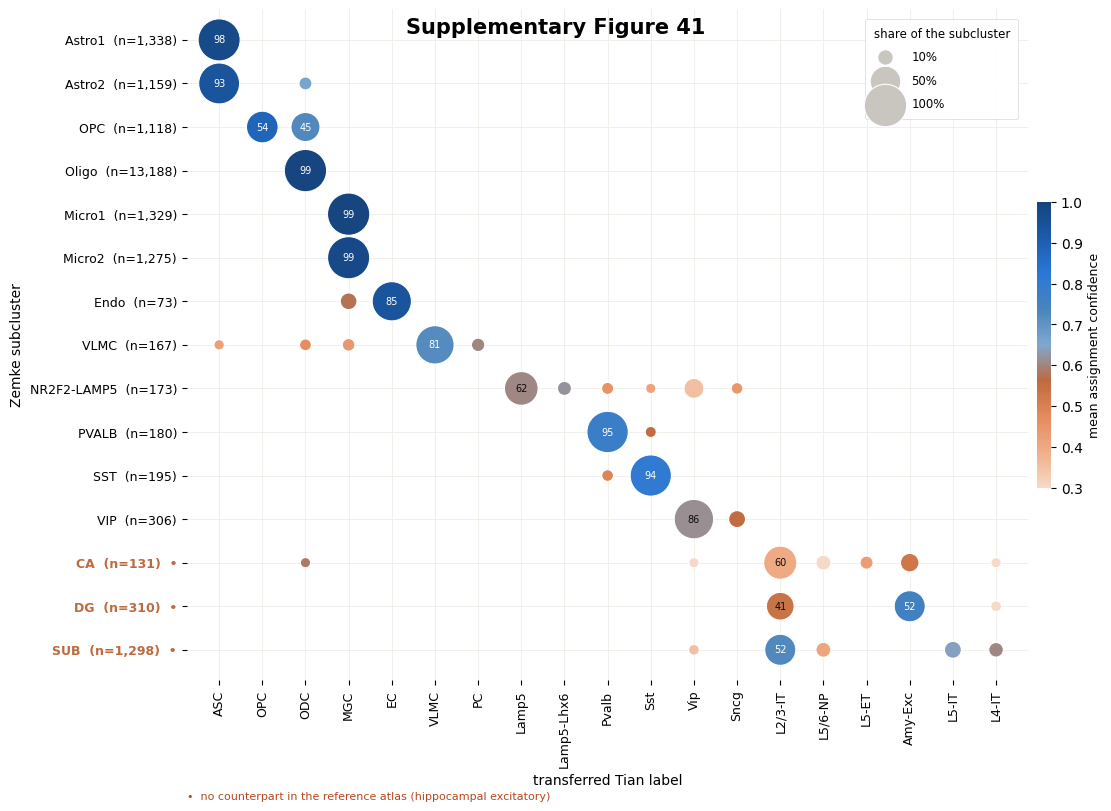

top assignment per subcluster, with the confidence behind it

subcluster     top label        share  mean conf
Astro1         ASC                98%      0.975
Astro2         ASC                93%      0.939
OPC            OPC                54%      0.884
Oligo          ODC                99%      0.991
Micro1         MGC                99%      0.990
Micro2         MGC                99%      0.977
Endo           EC                 85%      0.940
VLMC           VLMC               81%      0.720
NR2F2-LAMP5    Lamp5              62%      0.606
PVALB          Pvalb              95%      0.780
SST            Sst                94%      0.808
VIP            Vip                86%      0.614
CA             L2/3-IT            60%      0.401   <- no counterpart
DG             Amy-Exc            52%      0.761   <- no counterpart
SUB            L2/3-IT            52%      0.726   <- no counterpart


In [15]:
# Supplementary Figure 41 -- dot area = share, dot colour = mean confidence
from matplotlib.colors import Normalize

NOVEL = {"CA", "DG", "SUB"}
ROW_GROUPS = ["Astro1", "Astro2", "OPC", "Oligo", "Micro1", "Micro2", "Endo", "VLMC",
              "NR2F2-LAMP5", "PVALB", "SST", "VIP", "CA", "DG", "SUB"]
MINSHARE, COLMIN = 0.02, 0.05
CM_CONF = LinearSegmentedColormap.from_list("conf",
    ["#f7d9c8", "#f0ae89", "#e58a5c", "#bd6a3f", "#7fa8cf", "#4a84bb",
     "#2a78d6", "#1c5cab", "#15437c"])

present = set(yq)
qt = [t for t in ROW_GROUPS if t in present] + [t for t in sorted(present) if t not in ROW_GROUPS]
cand = sorted(set(pred))
share = np.zeros((len(qt), len(cand)))
cmean = np.full((len(qt), len(cand)), np.nan)
for i, a in enumerate(qt):
    m = yq == a
    for j, b in enumerate(cand):
        sel = m & (pred == b)
        if sel.any():
            share[i, j] = sel.sum() / m.sum()
            cmean[i, j] = conf_w[sel].mean()

kj = [j for j in range(len(cand)) if share[:, j].max() >= COLMIN]
kj.sort(key=lambda j: (int(np.argmax(share[:, j])), -float(share[:, j].max())))
keep = [cand[j] for j in kj]
M, CMx = share[:, kj], cmean[:, kj]

fig = plt.figure(figsize=(11.0, 8.0), constrained_layout=True)
fig.suptitle("Supplementary Figure 41", fontsize=15, fontweight="bold", y=0.985)
ax = fig.add_subplot(111)
ypos = np.arange(len(qt))[::-1]
norm = Normalize(0.3, 1.0)

xs, ys, ss, cs = [], [], [], []
for i, y in enumerate(ypos):
    for j in range(len(keep)):
        if M[i, j] >= MINSHARE:
            xs.append(j); ys.append(y); ss.append(34 + M[i, j] * 900); cs.append(CMx[i, j])
im = ax.scatter(xs, ys, s=ss, c=cs, cmap=CM_CONF, norm=norm,
                edgecolors="#ffffff", linewidths=0.8, zorder=3)
for i, y in enumerate(ypos):
    for j in range(len(keep)):
        if M[i, j] >= 0.30:
            ax.text(j, y, f"{M[i, j]*100:.0f}", ha="center", va="center", fontsize=7,
                    zorder=4, color="#ffffff" if norm(CMx[i, j]) > 0.55 else "#0b0b0b")

ax.set_xticks(range(len(keep))); ax.set_xticklabels(keep, rotation=90, fontsize=9)
ax.set_yticks(ypos)
ax.set_yticklabels([f"{t}  (n={int((yq==t).sum()):,})" + ("  •" if t in NOVEL else "")
                    for t in qt], fontsize=9)
for i, t in enumerate(qt):
    if t in NOVEL:
        ax.get_yticklabels()[i].set_color("#bd6a3f")
        ax.get_yticklabels()[i].set_fontweight("bold")
ax.set_xlabel("transferred Tian label", fontsize=10)
ax.set_ylabel("Zemke subcluster", fontsize=10)
ax.set_xlim(-0.75, len(keep) - 0.25); ax.set_ylim(-0.7, len(qt) - 0.3)
ax.grid(color="#eeede7", lw=0.6, zorder=0); ax.set_axisbelow(True)
for sp in ax.spines.values():
    sp.set_visible(False)

cb = fig.colorbar(im, ax=ax, fraction=0.017, pad=0.010)
cb.set_label("mean assignment confidence", fontsize=9); cb.outline.set_visible(False)
for frac, lab in ((0.10, "10%"), (0.50, "50%"), (1.00, "100%")):
    ax.scatter([], [], s=34 + frac * 900, c="#c8c6be", edgecolors="#ffffff",
               linewidths=0.8, label=lab)
lg = ax.legend(loc="upper right", bbox_to_anchor=(0.995, 0.995), ncol=1, frameon=True,
               framealpha=0.92, edgecolor="#dcdbd4", fontsize=8.5,
               title="share of the subcluster", title_fontsize=8.5,
               handletextpad=1.2, labelspacing=0.9, borderpad=0.7)
lg.get_frame().set_linewidth(0.6); lg._legend_box.align = "left"
ax.text(0.0, -0.165, "•  no counterpart in the reference atlas (hippocampal excitatory)",
        transform=ax.transAxes, fontsize=8, color="#b84821", ha="left", va="top")

fig.savefig(os.path.join(CACHE_DIR, "SuppFig41_dotmatrix.pdf"), dpi=400)
plt.show()

print("top assignment per subcluster, with the confidence behind it\n")
print(f"{'subcluster':14s} {'top label':14s} {'share':>7s} {'mean conf':>10s}")
for i, t in enumerate(qt):
    j = int(np.argmax(M[i]))
    print(f"{t:14s} {keep[j]:14s} {M[i, j]*100:6.0f}% {CMx[i, j]:10.3f}"
          + ("   <- no counterpart" if t in NOVEL else ""))
